In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# Import Libraries & Load Dataset

In [16]:
# Location of our historical international football dataset
data_path = Path("../Data/raw/results.csv")

# Load the dataset
df = pd.read_csv(data_path)

# Display dataset dimensions and first five rows
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (49945, 9)


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


# Data Quality Assessment

In [17]:
# Inspect dataset structure and data types
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicated records
print("\nDuplicate rows:", df.duplicated().sum())

# Check data coverage
print("\nEarliest match:", df["date"].min())
print("Latest match:", df["date"].max())

<class 'pandas.DataFrame'>
RangeIndex: 49945 entries, 0 to 49944
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   date        49945 non-null  str  
 1   home_team   49945 non-null  str  
 2   away_team   49945 non-null  str  
 3   home_score  49945 non-null  int64
 4   away_score  49945 non-null  int64
 5   tournament  49945 non-null  str  
 6   city        49945 non-null  str  
 7   country     49945 non-null  str  
 8   neutral     49945 non-null  bool 
dtypes: bool(1), int64(2), str(6)
memory usage: 3.1 MB

Missing values:
date          0
home_team     0
away_team     0
home_score    0
away_score    0
tournament    0
city          0
country       0
neutral       0
dtype: int64

Duplicate rows: 0

Earliest match: 1872-11-30
Latest match: 2026-10-06


# Historical Data Preparation

In [18]:
# Convert the date column into datetime format
df["date"] = pd.to_datetime(df["date"])


# Keep only matches played before the 2026 World Cup
df_historical = df[df["date"] < "2026-06-11"].copy()

# Sort matches chronologically
df_historical = df_historical.sort_values("date").reset_index(drop=True)

# Compare original and filtered datasets
print("Original matches:", len(df))
print("Historical matches:", len(df_historical))
print("Excluded matches:", len(df) - len(df_historical))

print("\nLatest historical match:")
print(df_historical["date"].max())

display(df_historical.tail())


Original matches: 49945
Historical matches: 49475
Excluded matches: 470

Latest historical match:
2026-06-10 00:00:00


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49470,2026-06-09,Hungary,Kazakhstan,3,1,Friendly,Debrecen,Hungary,False
49471,2026-06-10,England,Costa Rica,3,0,Friendly,Orlando,United States,True
49472,2026-06-10,Portugal,Nigeria,2,1,Friendly,Leiria,Portugal,False
49473,2026-06-10,Bolivia,Algeria,0,4,Friendly,Kansas City,United States,True
49474,2026-06-10,Afghanistan,Pakistan,0,2,Diamond Jubilee International Football Tournament,Malé,Maldives,True


# Match Outcome Labels

In [19]:
# Create a match outcome label based on the final score
df_historical["result"] = np.select(
    [
        df_historical["home_score"] > df_historical["away_score"],
        df_historical["home_score"] < df_historical["away_score"]
    ],
    ["H", "A"],
    default="D"
)

# Count how often each outcome occurs
print("Match outcome distribution:")
print(df_historical["result"].value_counts())

# Display the updated dataset
display(df_historical.head())

Match outcome distribution:
result
H    24251
A    13982
D    11242
Name: count, dtype: int64


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,result
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False,D
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False,H
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False,H
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False,D
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False,H


# EDA: Match Outcomes

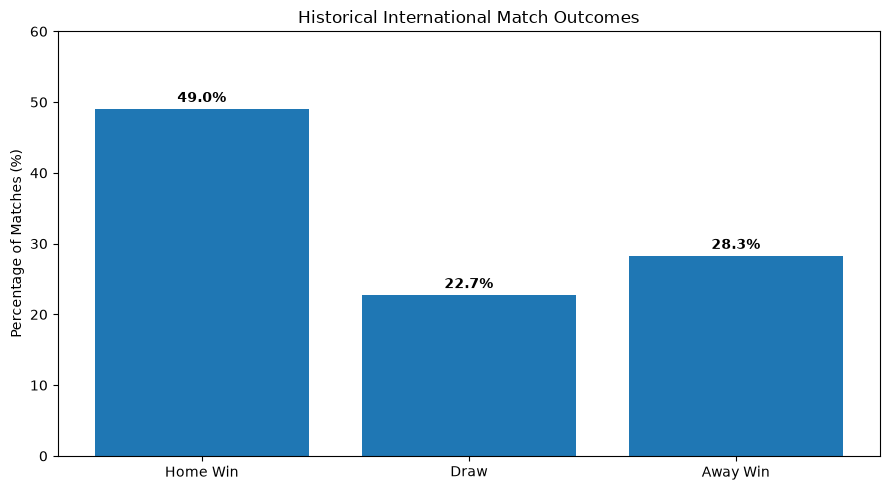

In [20]:
# Calculate match outcome percentages
outcome_pct = (
    df_historical["result"]
    .value_counts(normalize=True)
    .reindex(["H", "D", "A"])
    * 100
)

labels = ["Home Win", "Draw", "Away Win"]

# Create bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(labels, outcome_pct.values)

# Add percentage labels
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Historical International Match Outcomes")
ax.set_ylabel("Percentage of Matches (%)")
ax.set_ylim(0, 60)

plt.tight_layout()
plt.show()


## 6. Neutral vs Non-Neutral Match Analysis

Compare match outcome distributions between neutral and non-neutral venues to investigate the relationship between venue type and match results.

This analysis will help determine whether neutral venue status should be included as a feature in the machine-learning model.

In [21]:

# Calculate match outcome percentages by venue type
venue_outcomes = pd.crosstab(
    df_historical["neutral"],
    df_historical["result"],
    normalize="index"
) * 100

# Rename rows and columns for readability
venue_outcomes = venue_outcomes.rename(
    index={False: "Non-Neutral", True: "Neutral"},
    columns={"H": "Home Win", "D": "Draw", "A": "Away Win"}
)

# Arrange outcomes in a consistent order
venue_outcomes = venue_outcomes[
    ["Home Win", "Draw", "Away Win"]
]

display(venue_outcomes.round(2))


result,Home Win,Draw,Away Win
neutral,,,
Non-Neutral,50.75,22.84,26.41
Neutral,44.21,22.39,33.40
